# LangGraph 기초 실습: 자료를 보고 답할지 되물을지 정하기

**이 노트북에서 할 일**

1. Ch 12 문서 청크로 도서관 안내 창구 그래프를 하나 만듭니다.
2. 검색이 낸 점수와 기준값을 견줘 노드가 다음 길을 스스로 고르게 합니다.
3. 기준값 한 자리만 바꿔 다시 실행하고 두 실행이 지난 길을 견줍니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
서비스 요청은 모두 네 번입니다.
임베딩은 문서 청크 한 번과 질문 두 번이고 답을 쓰는 모델은 실행 1에서 한 번입니다.
예상 비용은 네 번을 합쳐 미화 0.01달러 아래입니다.
실행 시간은 패키지 설치를 빼면 1분 안팎입니다.

**데이터** — 읽는 파일은 07절과 같은 Ch 12 문서 파일 하나입니다.

- `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 문서 6건·문서 청크 175개)

**이 노트북은 파일을 쓰지 않습니다** — 결과는 화면에만 냅니다.
Ch 12 파일은 읽기만 하고 고치지 않습니다.

**강의와 실습 범위** — 이 절은 이 챕터의 실습입니다.
강사와 함께 첫 셀부터 차례로 실행하고 따로 내는 과제는 없습니다.
9~12절의 출력 두 벌과 표를 함께 읽습니다.

정의 셀은 여덟 개이고 하나는 상태 형식, 일곱은 이 절이 만든 함수입니다.
앞 절에서 배운 함수 일곱 개는 도구 파일에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 일곱 개를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part4/ch13-langgraph-basics`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 놓인 상자 일곱으로 맨 위 회색 상자 가상 시작점 START에서 화살표가 파란 상자 노드 normalize 질문 칸을 다듬음으로 이어지고 다시 파란 상자 노드 search_docs 보고 자리 칸과 점수 칸과 파란 상자 노드 route 판단 이유 칸과 다음 노드로 이어진 뒤 점선 화살표 둘이 파란 상자 노드 make_reply 모델을 부르는 노드와 파란 상자 노드 ask_more 적어 둔 안내 글로 갈라지고 두 상자가 맨 아래 회색 상자 가상 끝점 END로 모이는 그림](attachment:08-1-조립도.png)

위에서 아래로 읽습니다. 맨 위 회색 상자가 입력이 들어오는 자리입니다.

그 아래 파란 상자 다섯이 이 실습에서 만들 노드입니다.
셋째 상자에서 점선 화살표 둘이 갈라집니다.
점선은 노드가 낸 `Command`가 정하는 이동이고 실선은 우리가 적은 고정 엣지입니다.
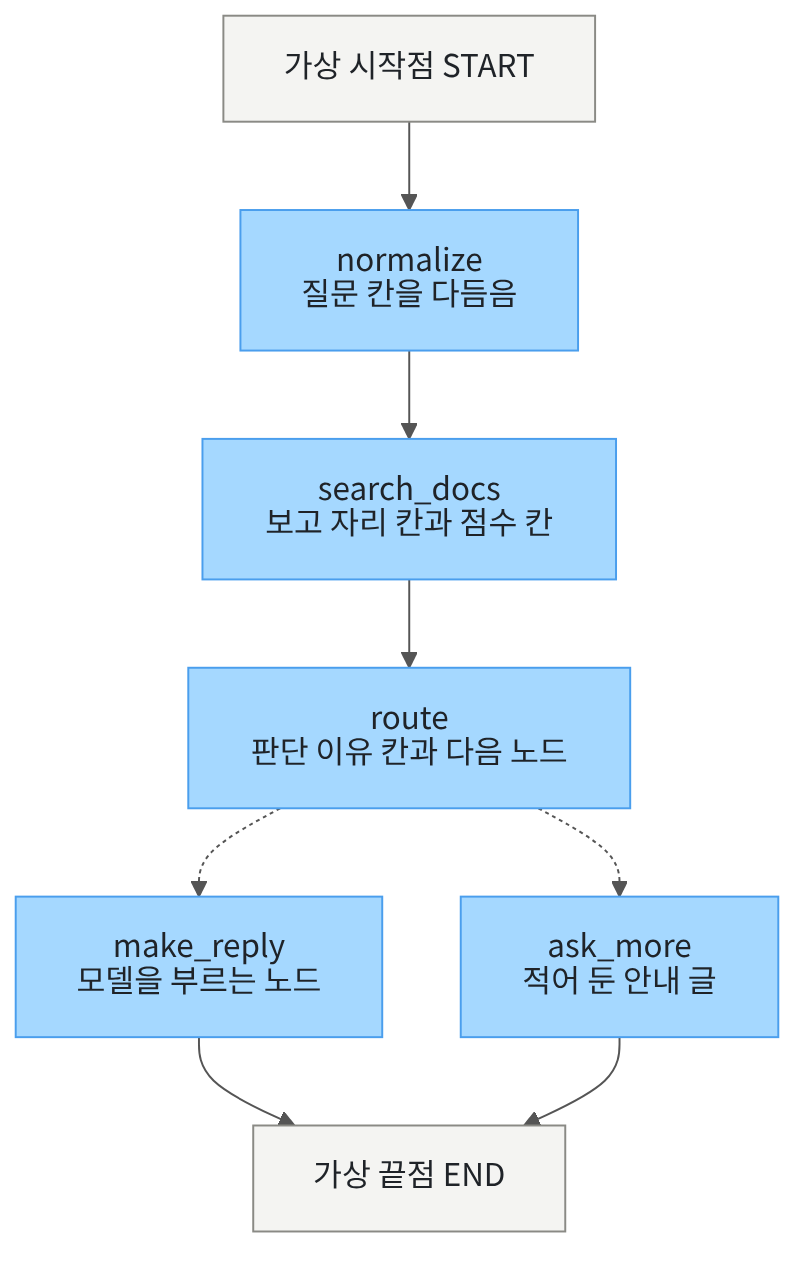

## 1. 준비

첫 셀은 패키지 일곱 개를 설치하고 설치된 판 번호를 출력합니다.
07절과 같은 일곱 개입니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2" "numpy==2.5.3"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 일곱 줄이 보입니다.
줄 `langgraph: 1.2.11`과 `rank-bm25: 0.2.2`가 보이면 다음 셀로 넘어갑니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이 실습이 쓸 이름 열여섯 개를 불러오고 도구 파일에서 함수 일곱 개를 가져옵니다.
01~06절에서 쓴 이름이 열하나이고 07절에서 쓴 이름이 다섯입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 02절 노드 `normalize`와 07절에서 쓴 Ch 12 함수 여섯 개를 가져옵니다.
인자 모양은 5절에서 설명합니다.

In [2]:
# 01~06절 그래프 이름과 07절 검색 도구 이름을 함께 불러옵니다
import json
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AnyMessage, HumanMessage, AIMessage
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.types import Command
from kiwipiepy import Kiwi
from rank_bm25 import BM25Okapi
from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# 02절 노드와 Ch 12 검색 함수 여섯 개를 도구 파일에서 가져옵니다
from rag_tools import fuse_rank, kiwi_terms, normalize, parent_ids_of
from rag_tools import rank_chunks_by_bm25, rank_chunks_by_distance, unique_chunk_ids

print("이 실습이 함께 쓰는 이름:", "add_messages", "Command", "OpenAIEmbeddings")

이 실습이 함께 쓰는 이름: add_messages Command OpenAIEmbeddings


**결과 읽기** — 출력 줄에 이 실습이 함께 쓰는 이름 셋이 보입니다.
리듀서 `add_messages`는 04절, 이동을 담는 `Command`는 06절, 임베딩을 만드는 `OpenAIEmbeddings`는 07절 이름입니다.
한 노트북에서 세 절 이름을 함께 쓰는 것이 이 실습의 자리입니다.
도구 파일에서 가져온 함수 일곱 개는 출력하지 않습니다.

## 2. 키와 모델 준비

이 챕터에서 모델을 부른 절은 07절 하나였습니다.
이 실습이 두 번째이자 마지막입니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 문장을 고르게 합니다.
설정 `reasoning_effort="none"`은 답을 쓰기 전에 따로 생각하는 단계를 두지 않게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 실습 주제 — 되물을지 답할지 노드가 정하기

작은 도서관 안내 창구를 맡았다고 봅니다.
이용자가 질문을 적으면 창구는 자료를 찾아보고 답을 씁니다.
찾은 자료에 질문 낱말이 거의 겹치지 않으면 답을 쓰는 대신 자료를 더 찾자고 적습니다.

이 판단을 노드 하나가 맡습니다.
06절 `Command`는 상태 갱신과 다음 노드 이름을 함께 냈습니다.
03·06절에서는 그 점수를 손으로 넣었지만 이번에는 검색이 낸 점수를 씁니다.

바꿔 볼 값은 기준값 한 자리입니다.
실행 1은 기준값을 낮게 두고 실행 2는 높게 둡니다.
질문과 문서와 두 순위에 줄 몫은 두 실행에서 같게 둡니다.

## 4. 재료 만들기 — Ch 12 자료와 값

먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
Ch 10~12와 07절에서 쓴 코드와 같습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄 `고른 경로` 뒤에 점 하나나 위로 올라가는 경로가 보입니다.
후보 셋 가운데 Ch 12 자료 폴더가 있는 자리를 고릅니다.

다음 셀은 Ch 12 문서 파일 하나를 읽습니다.

In [6]:
# Ch 12가 남긴 문서 파일을 읽습니다(읽기만 하고 고치지 않습니다)
chapter12_path = root_path + "/labs/part3/ch12-retrieval-tuning"
with open(chapter12_path + "/data/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))

부모 문서 수: 6
문서 청크 수: 175


**결과 읽기** — 출력 줄 `부모 문서 수: 6`과 `문서 청크 수: 175`가 07절과 같습니다.
Ch 12 07~13절이 쓴 자료와 같은 파일입니다.
07절이 함께 읽던 통합 기록 파일은 이번에 읽지 않습니다.
이 실습은 Ch 12 질문 대신 01절 질문을 씁니다.

다음 셀은 Ch 12에서 정한 값을 그대로 다시 적습니다.

In [7]:
# Ch 12 04~08절에서 정한 값을 그대로 다시 적습니다
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
report_place = 5
context_count = 3
equal_weights = [1.0, 1.0]
print("순위 상수:", rank_constant, "| 보고 자리:", report_place)
print("모델에 넣을 자리 수:", context_count)
print("두 순위에 줄 몫:", equal_weights)

순위 상수: 60 | 보고 자리: 5
모델에 넣을 자리 수: 3
두 순위에 줄 몫: [1.0, 1.0]


**결과 읽기** — 출력 줄 `순위 상수: 60 | 보고 자리: 5`는 Ch 12 06·08절 값입니다.
출력 줄 `모델에 넣을 자리 수: 3`은 보고 자리 앞에서 모델에 넣을 문서 청크 수입니다.
출력 줄 `두 순위에 줄 몫: [1.0, 1.0]`은 거리 순위와 낱말 순위를 같은 몫으로 합친다는 뜻입니다.
07절에서는 이 몫을 바꿔 봤지만 이번 실습에서는 두 실행 모두 같게 둡니다.

다음 셀은 이 실습이 쓸 질문과 기준값 두 개를 정합니다.

In [8]:
# 이 실습이 쓸 질문과 안내 글과 이번에 바꿔 볼 기준값 두 개를 정합니다
first_question = "  대출 기간은 며칠인가요?  "
notice_text = "자료를 더 찾아야 합니다"
low_gate = 5.0
high_gate = 9.0
prompt_head = "아래 자료만 보고 질문에 한국어로 답하세요.\n"
prompt_head = prompt_head + "답 끝에 [문서ID p.쪽] 모양으로 출처를 적으세요.\n\n"
print("첫 질문:", first_question)
print("첫 질문의 글자 수:", len(first_question))
print("실행 1 기준값:", low_gate, "| 실행 2 기준값:", high_gate)
print("자료가 모자랄 때 적어 둘 글:", notice_text)

첫 질문:   대출 기간은 며칠인가요?  
첫 질문의 글자 수: 17
실행 1 기준값: 5.0 | 실행 2 기준값: 9.0
자료가 모자랄 때 적어 둘 글: 자료를 더 찾아야 합니다


**결과 읽기** — 출력 줄 `첫 질문의 글자 수: 17`은 01절부터 쓴 질문 그대로입니다.
앞뒤에 빈칸이 있어 노드 `normalize`가 할 일이 남아 있습니다.
출력 줄 `실행 1 기준값: 5.0 | 실행 2 기준값: 9.0`이 이번에 바꿀 자리입니다.
출력 줄 `자료가 모자랄 때 적어 둘 글: 자료를 더 찾아야 합니다`는 03·06절 답 칸 글과 같습니다.

다음 셀은 문서 청크마다 제목과 본문을 이어 붙이고 ID로 찾을 짝을 만듭니다.
07절과 같은 코드입니다.

In [9]:
# 문서 청크마다 제목과 본문을 이어 붙이고 ID로 부모와 쪽과 본문을 찾을 짝을 만듭니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
page_by_chunk = {}
text_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
    page_by_chunk[chunk["chunk_id"]] = chunk["page"]
    text_by_chunk[chunk["chunk_id"]] = chunk_text
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", all_chunk_count)

이어 붙인 글 수: 175


## 5. 앞 절 함수의 인자 확인하기

앞 절 함수 일곱 개는 준비 셀에서 도구 파일로부터 가져왔습니다.
02절 노드 `normalize`는 8절 조립에서 첫 노드로 그대로 씁니다.
Ch 12 함수 여섯 개는 07절과 같은 것을 같은 인자로 부릅니다.
노트북에서 만든 값은 함수 안에서 읽지 않고 인자로 넘깁니다.

함수 `rank_chunks_by_distance()`는 질문 벡터, 문서 청크 벡터 목록, 문서 청크 ID 목록, 남길 개수를 받습니다.
함수 `rank_chunks_by_bm25()`는 BM25 모델, 질문의 검색 낱말 목록, 문서 청크 ID 목록, 남길 개수를 받습니다.
질문의 검색 낱말은 `kiwi_terms()`에 형태소 분석기와 남길 품사 표시 목록을 함께 넘겨 만듭니다.
함수 `fuse_rank()`는 순위 상수를, `parent_ids_of()`는 부모 문서 짝을 인자로 받습니다.

리랭커와 MMR은 이 실습에서 쓰지 않아 가져오지 않았습니다.
보고 자리 다섯 개는 합친 차례의 앞자리를 그대로 씁니다.

## 6. 검색 재료 마무리 — BM25 모델과 문서 청크 벡터

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [10]:
# 형태소 분석기를 만들고 문서 청크마다 검색 낱말 목록을 만들어 BM25 모델을 만듭니다
kiwi = Kiwi()
kiwi_corpus = []
for text_value in chunk_texts:
    kiwi_corpus.append(kiwi_terms(kiwi, text_value, keep_tags))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175


**결과 읽기** — 출력 줄 `BM25 모델이 본 문서 청크 수: 175`가 문서 청크 수와 같습니다.
문서 청크 하나마다 검색 낱말 목록 하나를 만들었습니다.
이 셀은 서비스 요청을 보내지 않습니다.

다음 셀은 문서 청크를 벡터로 바꿉니다.
이 실습에서 서비스에 보내는 첫 요청입니다.

In [11]:
# Ch 12·07절과 같은 모델로 문서 청크를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 Ch 9~12·07절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~12와 같은 값입니다.
출력 줄 `문서 청크 벡터 수: 175`로 문서 청크마다 벡터 하나를 받았습니다.
벡터 안의 숫자는 호출마다 아주 조금씩 달라져 소수 자리까지 같다고 보지 않습니다.

## 7. 상태 형식과 결과를 볼 기록 장치

이 실습 상태에는 검색 결과와 판단과 대화가 모두 담깁니다.
칸 구성이 01~07절과 달라 형식 이름도 새로 붙입니다.
실행 흔적 칸에는 02절 규칙을, 메시지 칸에는 04절 리듀서를 적습니다.

In [12]:
# 이 실습 그래프가 쓸 상태 형식을 칸 일곱 개로 적습니다
class GuideState(TypedDict):
    question: str
    gate: float
    score: float
    picked_ids: list[str]
    decision: str
    messages: Annotated[list[AnyMessage], add_messages]
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `gate`가 이번에 바꿔 볼 설정 자리이고 07절에서 「설정 칸」이라고 불렀습니다.
칸 `messages`와 칸 `trace`에만 규칙을 적었고 나머지 다섯 칸은 덮어쓰기가 됩니다.
한 상태에 칸마다 다른 리듀서를 적을 수 있다는 것은 04절에서 보았습니다.

다음 셀은 결과를 볼 기록 장치 둘입니다.
칸을 적는 함수와 메시지 목록을 적는 함수를 한 셀에 담았습니다.

In [13]:
# 상태의 칸 일곱 개를 적는 함수와 메시지 목록을 적는 함수를 만듭니다
def print_state(label, state):
    print(label)
    print("질문 칸 |", state["question"])
    print("기준값 칸 |", state["gate"])
    print("점수 칸 |", state["score"])
    print("보고 자리 칸 |", state["picked_ids"])
    print("판단 이유 칸 |", state["decision"])
    print("메시지 칸의 메시지 수 |", len(state["messages"]))
    print("실행 흔적 칸 |", state["trace"])


def print_messages(label, messages):
    print(label)
    for message in messages:
        print(message.type, "|", message.text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
보고 자리 칸은 다섯 개라 값을 그대로 적고 메시지 칸은 개수만 적습니다.
여러 줄로 나오는 메시지 목록은 04절처럼 따로 출력합니다.
메시지 번호는 실행마다 달라져 출력하지 않습니다.

다음 셀은 실행 하나를 기록 한 줄로 만드는 함수입니다.

In [14]:
# 실행 한 번을 기록 한 줄로 만듭니다
def run_row(run_name, state):
    row = {"실행": run_name}
    row["기준값 칸"] = state["gate"]
    row["점수 칸"] = state["score"]
    row["판단 이유 칸"] = state["decision"]
    row["마지막에 지난 노드"] = state["trace"][-1]
    row["메시지 수"] = len(state["messages"])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
06절 판과 견주면 기준값 칸과 메시지 수가 들어왔습니다.
이 실습이 견주는 값이 그 둘과 판단 이유 칸이기 때문입니다.

다음 셀은 기준값만 바꿔 처음 상태를 만드는 함수입니다.
03·06·07절에서 쓴 `new_state`와 같은 모양입니다.

In [15]:
# 기준값 칸만 다른 처음 상태를 만들어 냅니다
def new_state(gate_value):
    state = {"question": first_question, "gate": gate_value}
    state["score"] = 0.0
    state["picked_ids"] = []
    state["decision"] = ""
    state["messages"] = [HumanMessage(first_question)]
    state["trace"] = []
    return state

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메시지 칸에는 이용자가 적은 글을 그대로 담습니다.
검색에 쓸 질문 칸은 노드 `normalize`가 다듬습니다.
나머지 칸은 빈 값으로 두고 노드가 채우게 합니다.

## 8. 노드 다섯 만들기

부품 하나를 노드 하나로 옮깁니다.
노드마다 자기가 채울 칸과 실행 흔적 칸에 자기 이름만 담아 냅니다.
02절이 정한 약속을 다섯 노드가 모두 지킵니다.

첫 노드 `normalize`는 02절에서 만든 노드를 도구 파일에서 가져왔습니다.
질문 칸의 앞뒤 빈칸을 없애고 메시지 칸은 건드리지 않습니다.
이 절에서 새로 만드는 노드는 나머지 넷입니다.
다음 노드가 07절 검색 부품 넷을 한 자리에 모읍니다.

In [16]:
# 두 순위를 합쳐 보고 자리를 남기고 낱말 순위 1위의 점수를 점수 칸에 담아 냅니다
def search_docs(state):
    question_vector = embedding_model.embed_query(state["question"])
    distance_hits = rank_chunks_by_distance(question_vector, chunk_vectors, chunk_ids, all_chunk_count)
    question_terms = kiwi_terms(kiwi, state["question"], keep_tags)
    word_hits = rank_chunks_by_bm25(bm25_model, question_terms, chunk_ids, all_chunk_count)
    ranking_list = [unique_chunk_ids(distance_hits), unique_chunk_ids(word_hits)]
    fused_ids = fuse_rank(ranking_list, equal_weights, rank_constant)
    top_hit = word_hits[0]
    return {"picked_ids": fused_ids[:report_place], "score": top_hit["점수"], "trace": ["search_docs"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드 안에서 질문 하나를 벡터로 바꾸는 요청이 한 번 나갑니다.
두 순위를 합친 차례에서 앞자리 다섯을 보고 자리 칸에 담습니다.
낱말 순위 1위의 점수를 점수 칸에 담아 다음 노드가 읽게 합니다.

다음 노드가 이 실습의 가운데입니다.

In [17]:
# 점수 칸과 설정 칸의 기준값을 견줘 갱신과 다음 노드 이름을 함께 담아 냅니다
def route(state):
    if state["score"] >= state["gate"]:
        return Command(update={"decision": "자료가 넉넉함", "trace": ["route"]}, goto="make_reply")
    return Command(update={"decision": "자료가 모자람", "trace": ["route"]}, goto="ask_more")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 점수 칸과 설정 칸을 읽어 `Command` 하나를 냅니다.
담긴 갱신은 판단 이유 칸과 실행 흔적 칸이고 담긴 다음 노드 이름은 둘 가운데 하나입니다.
비교 `>=`는 기준값과 같은 점수를 넉넉한 쪽으로 보냅니다.

다음 노드가 자료가 넉넉할 때 지나는 길 끝입니다.

In [18]:
# 보고 자리 앞 세 자리의 본문과 출처 표시를 넣어 모델에게 답을 받습니다(모델 요청 1번)
def make_reply(state):
    context_text = ""
    for chunk_id in state["picked_ids"][:context_count]:
        source_label = "[" + parent_by_chunk[chunk_id] + " p." + str(page_by_chunk[chunk_id]) + "]"
        context_text = context_text + source_label + "\n" + text_by_chunk[chunk_id] + "\n\n"
    prompt_text = prompt_head + "질문: " + state["question"] + "\n\n자료:\n" + context_text
    reply = model.invoke(prompt_text)
    return {"messages": [reply], "trace": ["make_reply"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
보고 자리 앞 세 자리의 본문과 출처 표시를 이어 붙여 넣습니다.
넣는 것은 쪽 전체가 아니라 문서 청크 본문입니다.
받은 답은 모델이 만든 메시지 그대로 메시지 칸에 담습니다.

다음 노드가 자료가 모자랄 때 지나는 길 끝입니다.

In [19]:
# 자료가 모자랄 때 지날 노드로 적어 둔 안내 글을 메시지 칸에 담아 냅니다
def ask_more(state):
    notice = AIMessage(notice_text)
    return {"messages": [notice], "trace": ["ask_more"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 노드는 모델을 부르지 않고 적어 둔 글을 메시지 하나로 만듭니다.
그 메시지는 우리가 손으로 만든 것이고 모델이 쓴 답이 아닙니다.
04절에서 쓴 모양과 같습니다.

## 9. 조립과 구조 확인

설계 객체를 만들고 노드 다섯을 등록합니다.
노드 `route`에는 갈 수 있는 자리를 함께 적습니다.

In [20]:
# 설계 객체를 만들고 노드 다섯 개를 등록하면서 route의 목적지를 함께 적습니다
builder = StateGraph(GuideState)
builder.add_node("normalize", normalize)
builder.add_node("search_docs", search_docs)
builder.add_node("route", route, destinations=("make_reply", "ask_more"))
builder.add_node("make_reply", make_reply)
builder.add_node("ask_more", ask_more)
print("등록한 노드 수:", len(builder.nodes))

등록한 노드 수: 5


**결과 읽기** — 출력 줄 `등록한 노드 수: 5`가 보입니다.
07절과 같은 다섯이지만 갈래가 하나 있는 점이 다릅니다.

다음 셀은 고정 엣지만 적고 컴파일합니다.

In [21]:
# 고정 엣지 다섯 개를 적고 컴파일합니다
builder.add_edge(START, "normalize")
builder.add_edge("normalize", "search_docs")
builder.add_edge("search_docs", "route")
builder.add_edge("make_reply", END)
builder.add_edge("ask_more", END)
graph = builder.compile()
print("고정 엣지로 적은 수:", len(builder.edges))
print("컴파일 결과의 종류:", type(graph))

고정 엣지로 적은 수: 5
컴파일 결과의 종류: <class 'langgraph.graph.state.CompiledStateGraph'>


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 5`가 보입니다.
노드가 낸 `Command`가 정하는 이동은 이 수에 들어가지 않습니다.
출력 줄의 종류 이름 `CompiledStateGraph`는 01절부터 같습니다.

다음 셀은 그래프가 스스로 그린 구조 문자열을 봅니다.

In [22]:
# 그래프가 스스로 그린 구조 문자열에서 화살표가 있는 줄만 골라 출력합니다
structure_text = graph.get_graph().draw_mermaid()
print("구조 문자열에서 화살표가 있는 줄")
for line in structure_text.split("\n"):
    if "-->" in line or "-.->" in line:
        print(line.strip())

구조 문자열에서 화살표가 있는 줄
__start__ --> normalize;
normalize --> search_docs;
route -.-> ask_more;
route -.-> make_reply;
search_docs --> route;
ask_more --> __end__;
make_reply --> __end__;


**결과 읽기** — 라벨 줄 아래 일곱 줄이 나옵니다.
실선 다섯 줄이 우리가 적은 고정 엣지입니다.
점선 두 줄 `route -.-> ask_more;`와 `route -.-> make_reply;`가 목적지를 적어 둔 자리입니다.
줄이 나온 차례는 실행 차례가 아니므로 아래 실행 흔적 칸과 함께 읽습니다.

## 10. 실행 1 · 기준값을 낮게

실행 전에 예상해 봅니다.
질문 낱말이 그대로 있는 문서 청크가 있어 점수가 기준값 5.0을 넘을 것입니다.
그러면 노드 `make_reply`로 가서 모델이 답을 쓸 것입니다.

In [23]:
# 기준값을 낮게 넣고 그래프를 실행합니다(임베딩 요청 1번·모델 요청 1번)
run1_state = new_state(low_gate)
run1_result = graph.invoke(run1_state)
print_state("실행 1 결과", run1_result)
run1_parents = parent_ids_of(run1_result["picked_ids"], parent_by_chunk)
print("보고 자리의 부모 문서 차례:", run1_parents)
print_messages("실행 1 메시지 칸", run1_result["messages"])

실행 1 결과
질문 칸 | 대출 기간은 며칠인가요?
기준값 칸 | 5.0
점수 칸 | 7.64
보고 자리 칸 | ['E01-P03-C02', 'E02-P05-C02', 'E02-P05-C01', 'E02-P03-C04', 'H01-P04-C01']
판단 이유 칸 | 자료가 넉넉함
메시지 칸의 메시지 수 | 2
실행 흔적 칸 | ['normalize', 'search_docs', 'route', 'make_reply']
보고 자리의 부모 문서 차례: ['E01', 'E02', 'H01']
실행 1 메시지 칸
human |   대출 기간은 며칠인가요?  
ai | 도서 대출 기간은 14일입니다. 영상 자료는 7일입니다. [E01 p.3]


**결과 읽기** — 출력 줄 `점수 칸 | 7.64`가 낱말 순위 1위의 점수입니다.
기준값 `5.0`보다 커서 출력 줄 `판단 이유 칸 | 자료가 넉넉함`이 나왔습니다.
출력 줄 `실행 흔적 칸 | ['normalize', 'search_docs', 'route', 'make_reply']`에 이름 넷이 남았습니다.
출력 줄 `보고 자리의 부모 문서 차례: ['E01', 'E02', 'H01']`로 보고 자리 다섯이 세 문서에서 왔습니다.
라벨 줄 `실행 1 메시지 칸` 아래 둘째 줄이 모델이 쓴 답이고 끝에 출처 표시가 붙었습니다.

## 11. 실행 2 · 기준값 한 자리만 올려서

바꿀 값은 기준값 하나입니다.
그래프도 노드도 질문도 그대로 두고 설정 칸만 바꿉니다.

실행 전에 예상해 봅니다.
점수는 같은 `7.64`인데 기준값이 9.0으로 올라 모자란 쪽으로 갈 것입니다.

In [24]:
# 기준값 한 자리만 올려 같은 그래프를 다시 실행합니다(임베딩 요청 1번)
run2_state = new_state(high_gate)
run2_result = graph.invoke(run2_state)
print_state("실행 2 결과", run2_result)
run2_parents = parent_ids_of(run2_result["picked_ids"], parent_by_chunk)
print("보고 자리의 부모 문서 차례:", run2_parents)
print_messages("실행 2 메시지 칸", run2_result["messages"])

실행 2 결과
질문 칸 | 대출 기간은 며칠인가요?
기준값 칸 | 9.0
점수 칸 | 7.64
보고 자리 칸 | ['E01-P03-C02', 'E02-P05-C02', 'E02-P05-C01', 'E02-P03-C04', 'H01-P04-C01']
판단 이유 칸 | 자료가 모자람
메시지 칸의 메시지 수 | 2
실행 흔적 칸 | ['normalize', 'search_docs', 'route', 'ask_more']
보고 자리의 부모 문서 차례: ['E01', 'E02', 'H01']
실행 2 메시지 칸
human |   대출 기간은 며칠인가요?  
ai | 자료를 더 찾아야 합니다


**결과 읽기** — 출력 줄 `점수 칸 | 7.64`는 실행 1과 같습니다.
기준값 `9.0`보다 작아서 출력 줄 `판단 이유 칸 | 자료가 모자람`이 나왔습니다.
출력 줄 `실행 흔적 칸 | ['normalize', 'search_docs', 'route', 'ask_more']`의 마지막 이름이 달라졌습니다.
라벨 줄 `실행 2 메시지 칸` 아래 둘째 줄은 적어 둔 안내 글이고 모델을 부르지 않았습니다.
출력 줄 `보고 자리 칸 | ['E01-P03-C02', 'E02-P05-C02', 'E02-P05-C01', 'E02-P03-C04', 'H01-P04-C01']`은 실행 1과 같습니다.

## 12. 두 실행을 기록 한 줄씩으로

마지막으로 두 실행의 기록을 한 표로 모읍니다.

실행 전에 예상해 봅니다.
점수 칸과 보고 자리 칸은 같고 판단 이유 칸과 마지막 노드만 갈릴 것입니다.

In [25]:
# 두 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("실행 1", run1_result))
run_rows.append(run_row("실행 2", run2_result))
print("실행 | 기준값 칸 | 점수 칸 | 판단 이유 칸 | 마지막에 지난 노드 | 메시지 수")
for row in run_rows:
    print(row["실행"], "|", row["기준값 칸"], "|", row["점수 칸"], "|", row["판단 이유 칸"], "|", row["마지막에 지난 노드"], "|", row["메시지 수"])
print("두 실행의 점수 칸이 같은가:", run1_result["score"] == run2_result["score"])
print("두 실행의 보고 자리 칸이 같은가:", run1_result["picked_ids"] == run2_result["picked_ids"])
print("두 실행의 실행 흔적 칸이 같은가:", run1_result["trace"] == run2_result["trace"])

실행 | 기준값 칸 | 점수 칸 | 판단 이유 칸 | 마지막에 지난 노드 | 메시지 수
실행 1 | 5.0 | 7.64 | 자료가 넉넉함 | make_reply | 2
실행 2 | 9.0 | 7.64 | 자료가 모자람 | ask_more | 2
두 실행의 점수 칸이 같은가: True
두 실행의 보고 자리 칸이 같은가: True
두 실행의 실행 흔적 칸이 같은가: False


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
두 줄의 점수 칸은 `7.64`로 같고 기준값 칸과 판단 이유 칸이 갈렸습니다.
출력 줄 `두 실행의 보고 자리 칸이 같은가: True`로 검색 결과는 같았습니다.
출력 줄 `두 실행의 실행 흔적 칸이 같은가: False`가 갈린 자리입니다.

## 정리

1. 01절 노드와 07절 검색과 06절 `Command`와 04절 메시지 칸을 한 그래프에 붙였습니다.
2. 검색이 낸 점수가 기준값을 넘는지에 따라 노드가 다음 길을 스스로 골랐습니다.
3. 설정 칸의 기준값 한 자리만 바꾸자 같은 검색 결과에서 지난 길이 갈렸습니다.

이 절로 Ch 13이 끝납니다. Ch 14에서는 검색 앞뒤에 붙이는 RAG 패턴을 배웁니다.